In [1]:
import sys
import os
import pandas as pd

sys.path.append(os.path.abspath('..'))

from quinex_application.visualisation.spatial_visualisation import SpatialVisualisation
from quinex_application.postprocessing.data_loading import load_property_data
from quinex_application.postprocessing.data_processing import (
    describe_corpus, save_text_availability_split,
    load_text_availability_split, merge_text_availability_splits,
)
from quinex_application.visualisation.plot_utils import show_figure

# True: temporal/spatial plots use only records from full-text publications
# (incl. IQR filter, aggregates, regression and all statistics derived from the plots)
FULL_TEXT_ONLY = False
CORPUS = "full_text" if FULL_TEXT_ONLY else "all"  # suffix for saved files

TECHNOLOGIES_NAN_PATH = "../data/visualisation_files/df_technologies_nan.parquet"
UNIT = "http://qudt.org/vocab/unit/"
# Contributing DOIs per figure, to merge counts of panels combined from several notebooks
CONTRIBUTING_DOIS_DIR = "../data/figures/contributing_dois"

**Corpus:** set `FULL_TEXT_ONLY` in the first cell to `False` (default: full text and abstract-only publications) or `True` (only records from full-text publications). It is passed to the plot functions as `full_text_only`, which restrict every dataset before any filtering, so all statistics (IQR filter, aggregates, regression slope, MAE, data tables) refer to the selected corpus. Every figure states the corpus and the number of contributing publications below the plot, and saved files get the suffix `_all` / `_full_text`.

In [2]:
visualisation = SpatialVisualisation()

### **Import Results**

In [19]:
cost_lcoh = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_lcoh.xlsx")

In [23]:
cost_lcoh["entity_mapping"].value_counts().head(20)

entity_mapping
Hydrogen                       204
Green Hydrogen                  80
Electrolyzer                    79
PV                              56
Wind                            45
Hybrid Energy System            16
Bioenergy                       14
CCS                              6
Nuclear                          4
Blue Hydrogen                    3
Grey Hydrogen                    3
Liquefied Natural Gas (LNG)      3
DAC                              3
Geothermal                       2
Lead Acid Battery                1
Hydropower                       1
Coal                             1
Offshore Wind                    1
Battery                          1
Natural Gas                      1
Name: count, dtype: int64

In [27]:
cost_lcoh[cost_lcoh["entity_base_mapping"] == "Hydrogen"]["property"].value_counts().tail(33)

property
average cost of hydrogen production                                1
lowest levelized cost of hydrogen (LCOH)                           1
levelized cost of storage                                          1
cost of the hydrogen production (COH)                              1
levelized hydrogen production cost (LPC)                           1
purchasing costs of hydrogen                                       1
total cost of producing hydrogen                                   1
cost of hydrogen distribution                                      1
average cost of Hydrogen                                           1
cost of hydrogen production                                        1
marginal cost per additional unit of stored useful energy          1
cost of converting 100% of the power of a wind farm to hydrogen    1
potential LCOH                                                     1
costs for the liquefaction, storage, and shipping of hydrogen      1
average cost of delivered

In [18]:
cost_lcoh[cost_lcoh["entity_base_mapping"] == "Hydrogen"]["property"].value_counts().head(20)

property
cost                                 229
LCOH                                  97
costs                                 75
production costs                      74
production cost                       48
levelized cost of hydrogen (LCOH)     25
levelized cost of hydrogen            20
levelized cost                        16
hydrogen cost                         15
Levelized Cost of Hydrogen (LCOH)     12
cost of hydrogen                      10
CAPEX                                  7
LCoH                                   6
total cost                             5
capital cost                           5
storage cost                           5
levelized costs                        5
unit cost                              4
levelised cost of hydrogen             4
minimum LCOH                           4
Name: count, dtype: int64

#### **LCOE**

In [3]:
cost_lcoe = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_lcoe2024.xlsx")
cost_lcoe = cost_lcoe[cost_lcoe["entity_base_mapping"].isin(['PV'])]

In [4]:
cost_lcoe = visualisation.convert_spatial(cost_lcoe, spatial_col="spatial_scope")
print(cost_lcoe["entity_base_mapping"].value_counts())

entity_base_mapping
PV    885
Name: count, dtype: int64


In [5]:
cost_lcoe = cost_lcoe[cost_lcoe["value_converted"] < 510]
len(cost_lcoe)

757

### **Visualize Results**


=== World Plot Generation Summary ===
[1] c) PV (choropleth) | IQR removed: 0 values (before=757, after=757)
    Contributing studies (DOI): 418 unique DOI(s) (full text: 365, abstract only: 53)
[2] d) PV (points) | IQR removed: 0 values (before=757, after=757)
    Contributing studies (DOI): 418 unique DOI(s) (full text: 365, abstract only: 53)
[3] c) PV (size) | IQR filter not applied in size mode
    Contributing studies (DOI): 415 unique DOI(s) (full text: 362, abstract only: 53)
Total contributing studies in this generated figure: 418 unique DOI(s) (full text: 365, abstract only: 53)
Corpus: All publications (full text and abstract only); n = 418 publications (full text: 365, abstract only: 53)


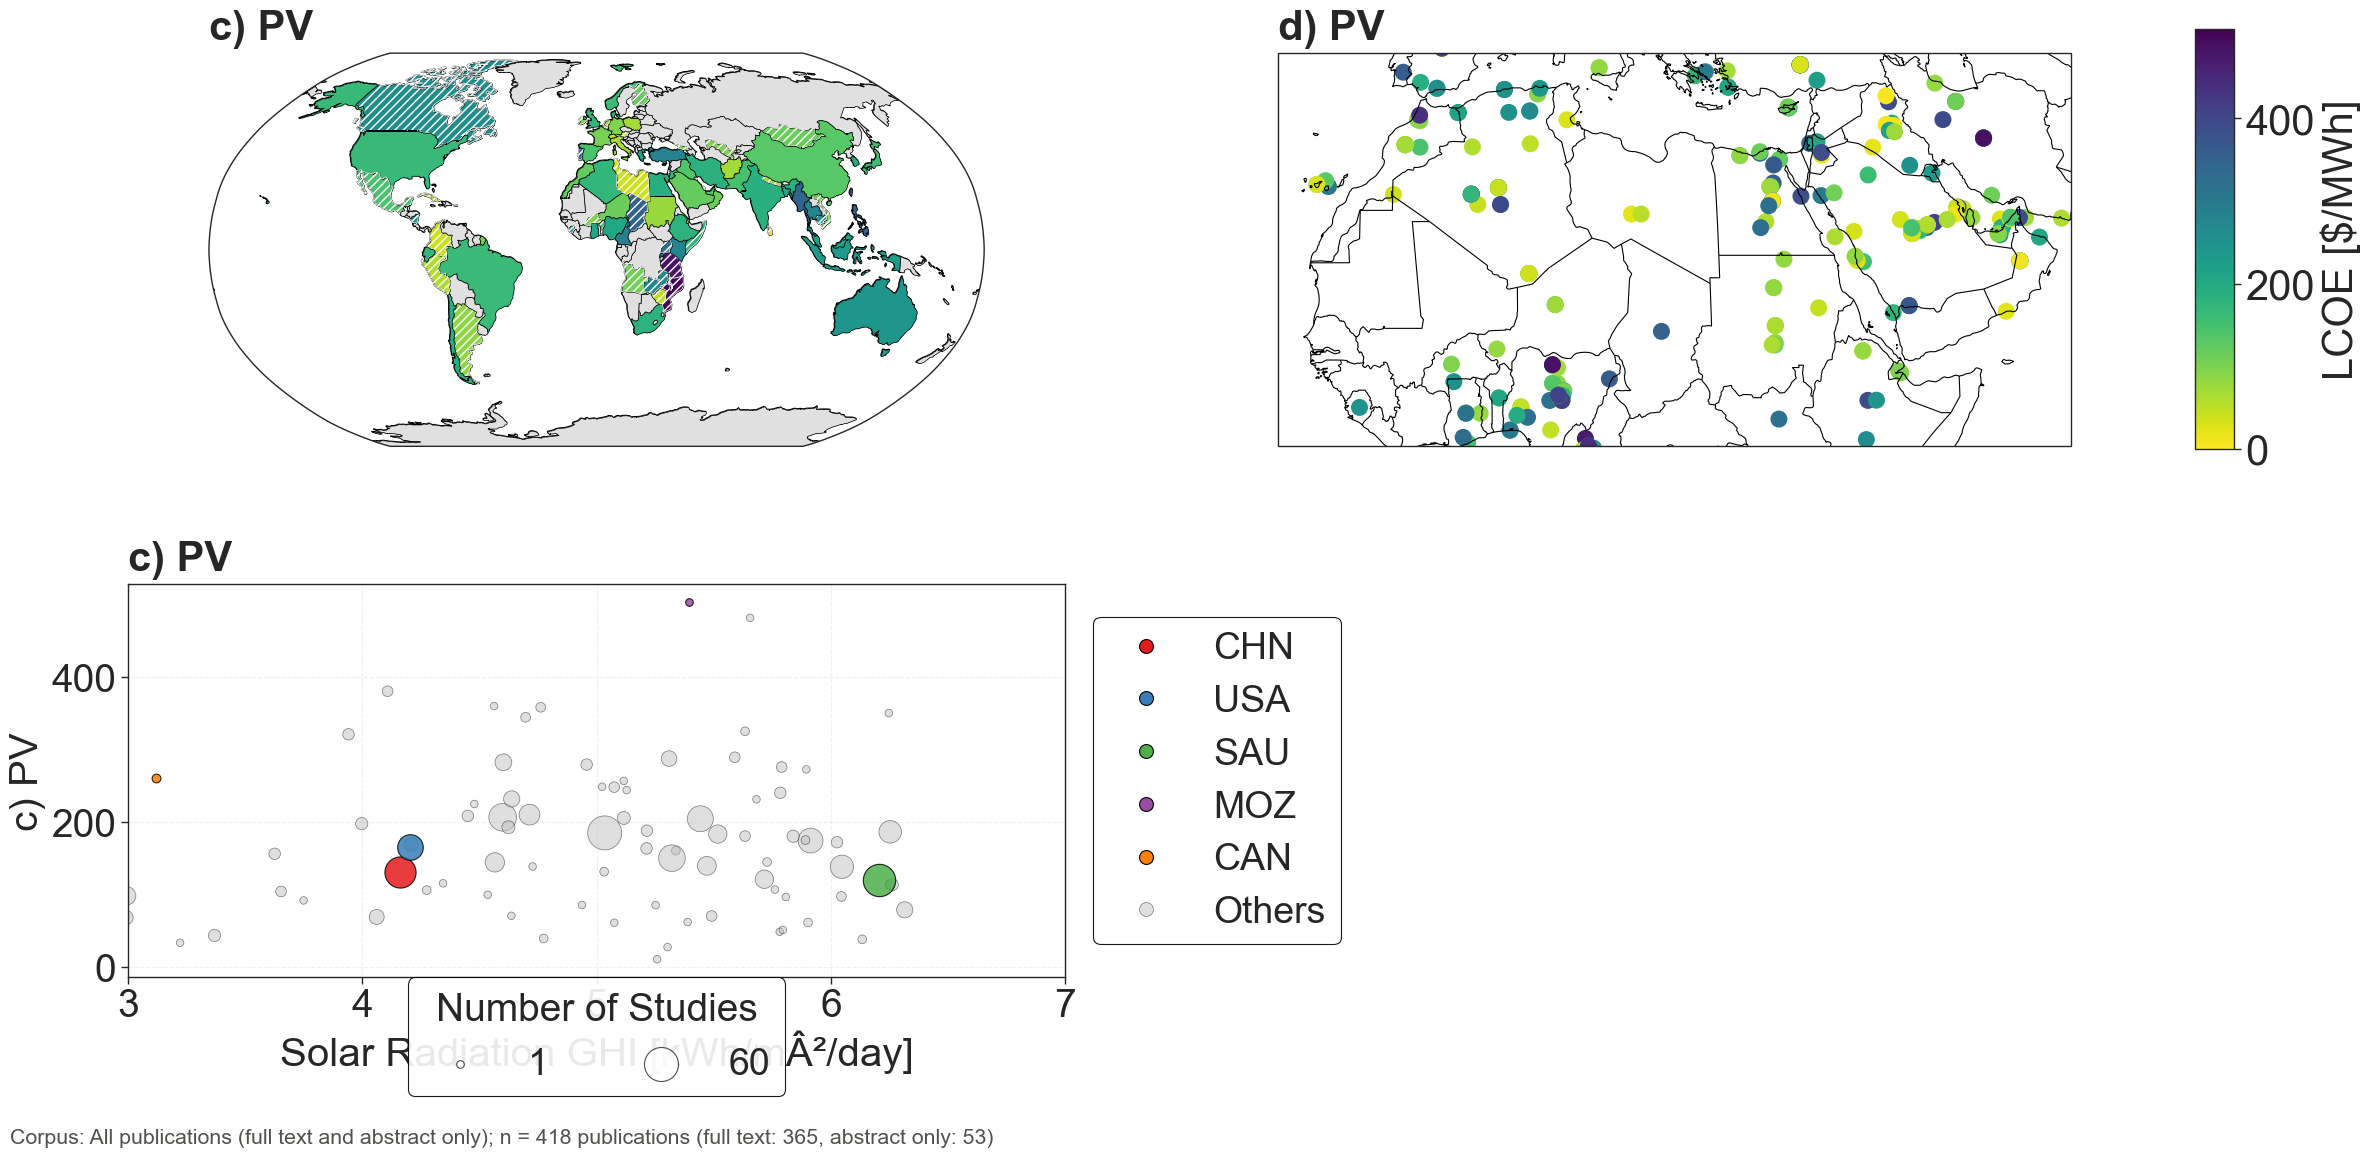

In [6]:
datasets = [
    {
    'df': cost_lcoe,
    'value_column': 'value_converted',
    'title': 'c) PV',
    'plot_mode': 'choropleth',
    'min_datapoints': 3,
    },
    {
    'df': cost_lcoe,
    'value_column': 'value_converted',
    'title': 'd) PV',
    'plot_mode': 'points',
    'spatial_extent': [-20, 60, 5, 40],
    },
    {
    'df': cost_lcoe,
    'value_column': 'value_converted',
    'title': 'c) PV',
    'plot_mode': 'size',
    'ghi_data_path': "../data/visualisation_files/ghi/country_GHI_mean.xlsx",
    'highlight_countries': ['CHN', 'USA', 'SAU', 'MOZ', 'CAN'],
    'x_range': [3,7],
    #'min_datapoints': 5,
    #'show_regression': True,
    },
]

fig, data_tables = visualisation.plot_multiple_datasets_on_world(
    datasets,
    cmap="viridis_r",
    colorbar_title="LCOE [$/MWh]",
    figsize=(26, 12),
    jitter_strength=0,
    default_point_size=150,
    font_size=30,
    #color_scale_range=(0, 520),
    #colorbar_ticks=[0, 100, 200, 300, 400, 500],
    iqr_lower_quantile=0.25,
    iqr_upper_quantile=0.75,
    iqr_multiplier=3,
    full_text_only=FULL_TEXT_ONLY,
)

show_figure(fig)
# show_figure(fig, save_path=f"../data/figures/results/spatial/lcoe_pv_new2_{CORPUS}.pdf")

### **Number of Scenarios**

In [7]:
# Only load this property (the full file needs ~7.5 GB RAM)
number_scenarios = load_property_data(
    TECHNOLOGIES_NAN_PATH, "Number of Scenarios", unit_uris=UNIT + "UNITLESS"
)
number_scenarios["unit_normalized"].apply(lambda units: units[0]["unit_uri"]).value_counts()

unit_normalized
http://qudt.org/vocab/unit/UNITLESS    33962
Name: count, dtype: int64

In [8]:
number_scenarios = visualisation.convert_spatial(number_scenarios, spatial_col="spatial_scope")
print(number_scenarios["property_base_mapping"].value_counts())

property_base_mapping
Number of Scenarios    2597
Name: count, dtype: int64



=== World Plot Generation Summary ===
[1] b (choropleth) | IQR removed: 245 values (before=2597, after=2352)
    Contributing studies (DOI): 1508 unique DOI(s) (full text: 1337, abstract only: 171)
[2] c (points) | IQR removed: 245 values (before=2597, after=2352)
    Contributing studies (DOI): 1508 unique DOI(s) (full text: 1337, abstract only: 171)
[3] d (points) | IQR removed: 245 values (before=2597, after=2352)
    Contributing studies (DOI): 1508 unique DOI(s) (full text: 1337, abstract only: 171)
[4] e (points) | IQR removed: 245 values (before=2597, after=2352)
    Contributing studies (DOI): 1508 unique DOI(s) (full text: 1337, abstract only: 171)
Total contributing studies in this generated figure: 1508 unique DOI(s) (full text: 1337, abstract only: 171)
Corpus: All publications (full text and abstract only); n = 1,508 publications (full text: 1,337, abstract only: 171)


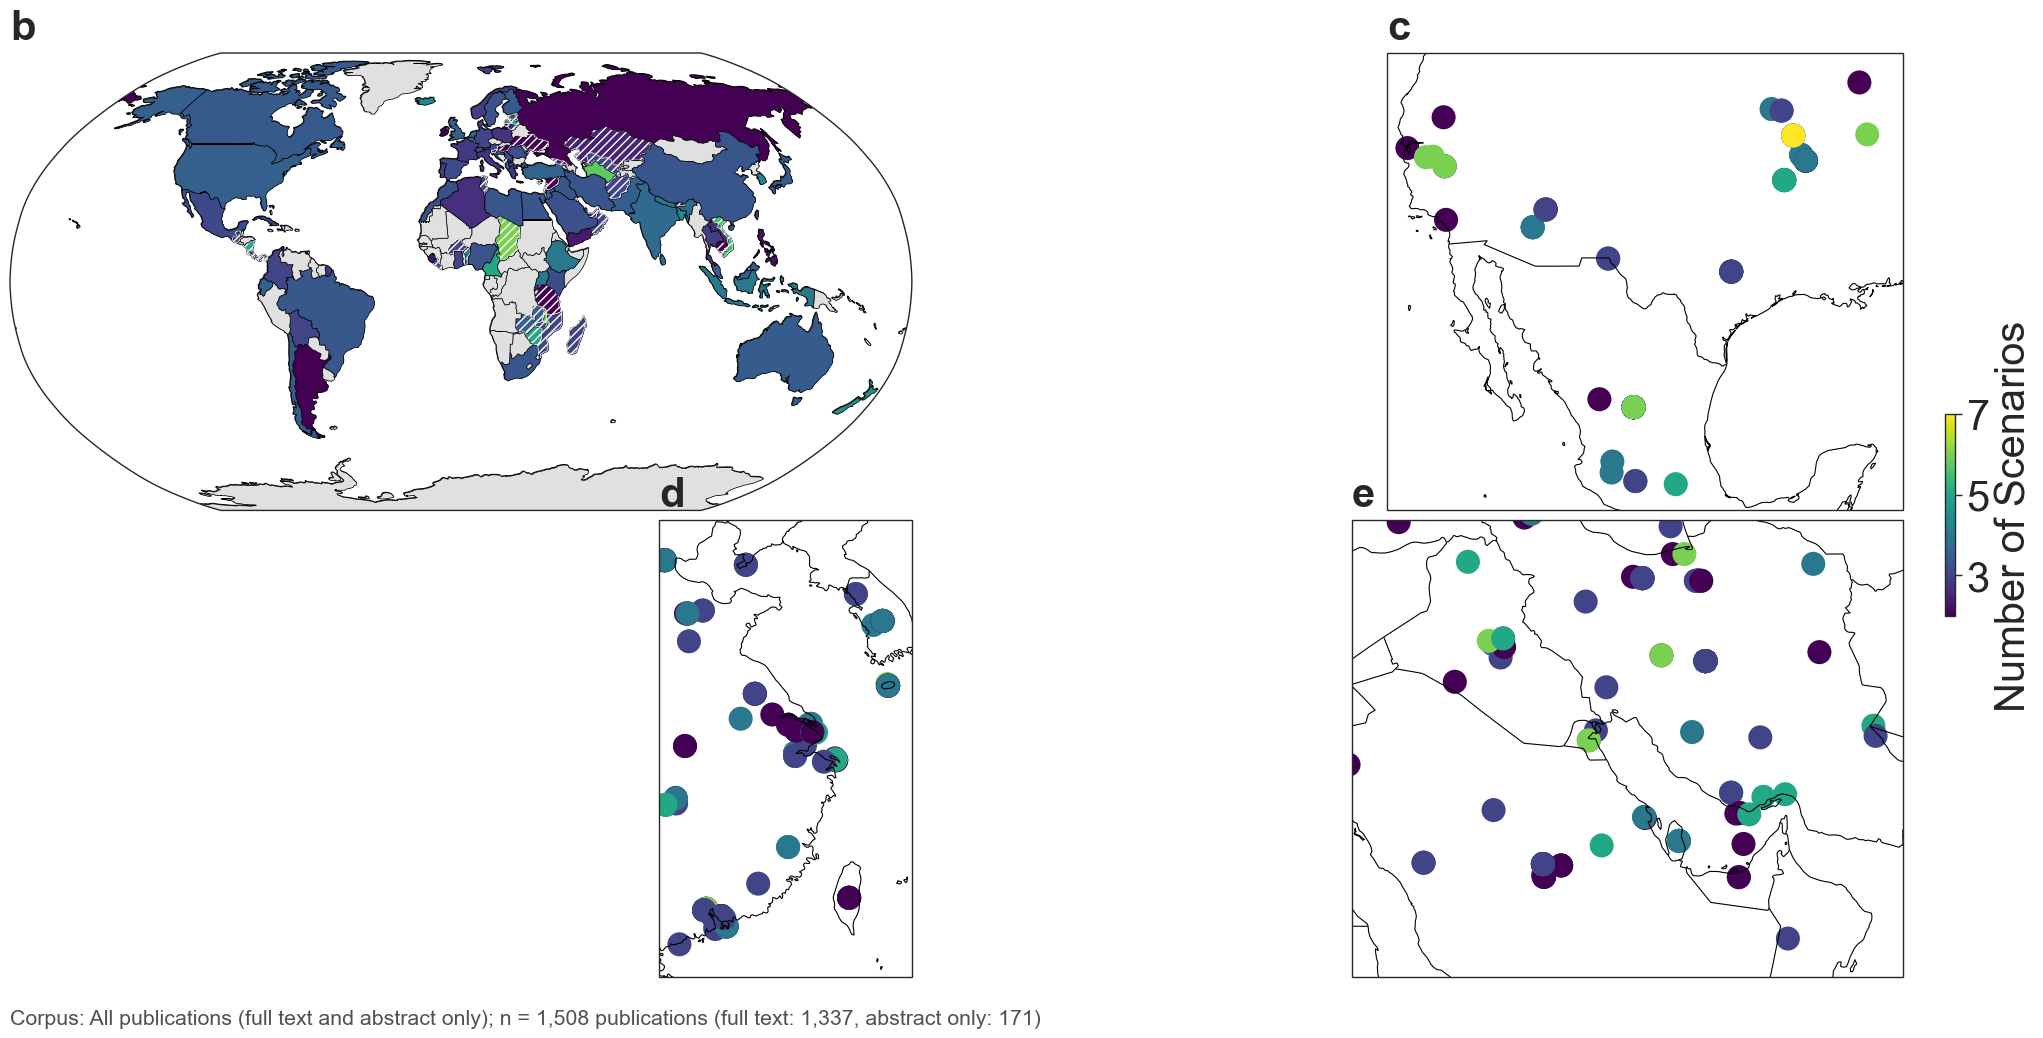

In [9]:
datasets = [
    {
    'df': number_scenarios,
    'value_column': 'value_normalized',
    'title': 'b',
    'plot_mode': 'choropleth',
    'min_datapoints': 3,
    },
    {
    'df': number_scenarios,
    'value_column': 'value_normalized',
    'title': 'c',
    'plot_mode': 'points',
    'spatial_extent': [-117, -92, 18, 43],
    },
    {
    'df': number_scenarios,
    'value_column': 'value_normalized',
    'title': 'd',
    'plot_mode': 'points',
    'spatial_extent': [118.0, 123.5, 20.0, 41.0],
    },
    # {
    # 'df': number_scenarios,
    # 'value_column': 'value_normalized',
    # 'title': 'e',
    # 'plot_mode': 'points',
    # 'spatial_extent': [0, 15, 41.0, 51],
    # },
    {
    'df': number_scenarios,
    'value_column': 'value_normalized',
    'title': 'e',
    'plot_mode': 'points',
    'spatial_extent': [38, 61, 20, 38],
    },
]

fig, data_tables = visualisation.plot_multiple_datasets_on_world(
    datasets,
    colorbar_title="Number of Scenarios",
    figsize=(26, 12),
    jitter_strength=0,
    default_point_size=300,
    font_size=30,
    color_scale_range=(2, 7),
    colorbar_ticks=[3, 5, 7],
    iqr_lower_quantile=0.25,
    iqr_upper_quantile=0.75,
    iqr_multiplier=3,
    full_text_only=FULL_TEXT_ONLY,
)

show_figure(fig)
save_text_availability_split(
    visualisation.last_contributing_split,
    f"{CONTRIBUTING_DOIS_DIR}/number_scenarios_{CORPUS}.json",
)
# show_figure(fig, save_path=f"../data/figures/results/spatial/number_scenarios_{CORPUS}.pdf")

### **Merged Publication Count: Number of Nodes, Time Steps and Scenarios**

The temporal panels (Number of Nodes, Number of Time Steps; Step 5) and the spatial panels (Number of Scenarios; above) are combined in one figure. A publication contributing to several panels is counted once. Run Step 5 with the same `FULL_TEXT_ONLY` setting first.

In [10]:
panel_splits = {
    "Number of Nodes / Time Steps (Step 5)": load_text_availability_split(
        f"{CONTRIBUTING_DOIS_DIR}/number_nodes_timesteps_{CORPUS}.json"
    ),
    "Number of Scenarios (Step 6)": load_text_availability_split(
        f"{CONTRIBUTING_DOIS_DIR}/number_scenarios_{CORPUS}.json"
    ),
}
for name, split in panel_splits.items():
    print(f"{name}: {describe_corpus(CORPUS, split=split)}")

merged_split = merge_text_availability_splits(list(panel_splits.values()))
overlap = set.intersection(*[s["full_text"] | s["abstract_only"] for s in panel_splits.values()])
print(f"\nMerged figure: {describe_corpus(CORPUS, split=merged_split)}")
print(f"Publications contributing to both parts: {len(overlap):,}")

Number of Nodes / Time Steps (Step 5): Corpus: All publications (full text and abstract only); n = 3,616 publications (full text: 3,245, abstract only: 371)
Number of Scenarios (Step 6): Corpus: All publications (full text and abstract only); n = 1,508 publications (full text: 1,337, abstract only: 171)

Merged figure: Corpus: All publications (full text and abstract only); n = 4,986 publications (full text: 4,445, abstract only: 541)
Publications contributing to both parts: 138
